In [2]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [3]:
title = "# week 6 - Exercises: Nested sampling and slice sampling"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# week 6 - Exercises: Nested sampling and slice sampling

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

We use the two targets from last week: the 1D Gamma distribution from the lecture and the 2D Gaussian from the Metropolis-Hastings exercise.

In [4]:
# 1D target from the lecture
target_distr_1d = scipy.stats.gamma(a=3, scale=1/3)

# 2D Gaussian from the Metropolis-Hastings exercise
sigma_x = 1
sigma_y = 2
rho = 0.7

mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Exact samples, to compare your samplers against
np.random.seed(42)
true_samples = bivariate_normal.rvs(size=10_000)

### Exercise 0: Why slice sampling?

*Nothing to implement here: read this and run the cell below.*

Last week we saw two ways to sample from a distribution $p(x)$:
- **Rejection sampling** gives independent samples, but needs a proposal $q$ and a constant $M$ with $Mq(x) > p(x)$ everywhere. In many dimensions almost every point is rejected.
- **Metropolis-Hastings** works in many dimensions, but you have to choose the proposal width. Too small, and the chain moves very slowly; too large, and almost every jump is rejected. The right width depends on $p$, which you do not know beforehand.

**Slice sampling** keeps the Markov chain approach of Metropolis-Hastings, but removes most of the tuning:
- It uses the same idea as rejection sampling: points spread uniformly under the curve $p(x)$ give samples of $p$.
- Each step picks a random height $u$ below $p(x_t)$, then a new point $x_{t+1}$ from the *slice*, where $p(x) > u$ (see the plot below).
- The interval that searches for the slice adapts by itself: it grows if it is too small and shrinks if it is too large. The step size $w$ only changes the speed, not the result.
- No step is wasted: the chain always moves to a new point.

**When to use it:** problems with a few to a moderate number of parameters, when you do not want to tune a proposal. It is also used inside nested sampling codes to find new live points (Exercises 3 and 4).

**When not:** for strongly correlated parameters, updating one coordinate at a time is slow. For very many parameters, methods that use gradients, like Hamiltonian Monte Carlo, work better.

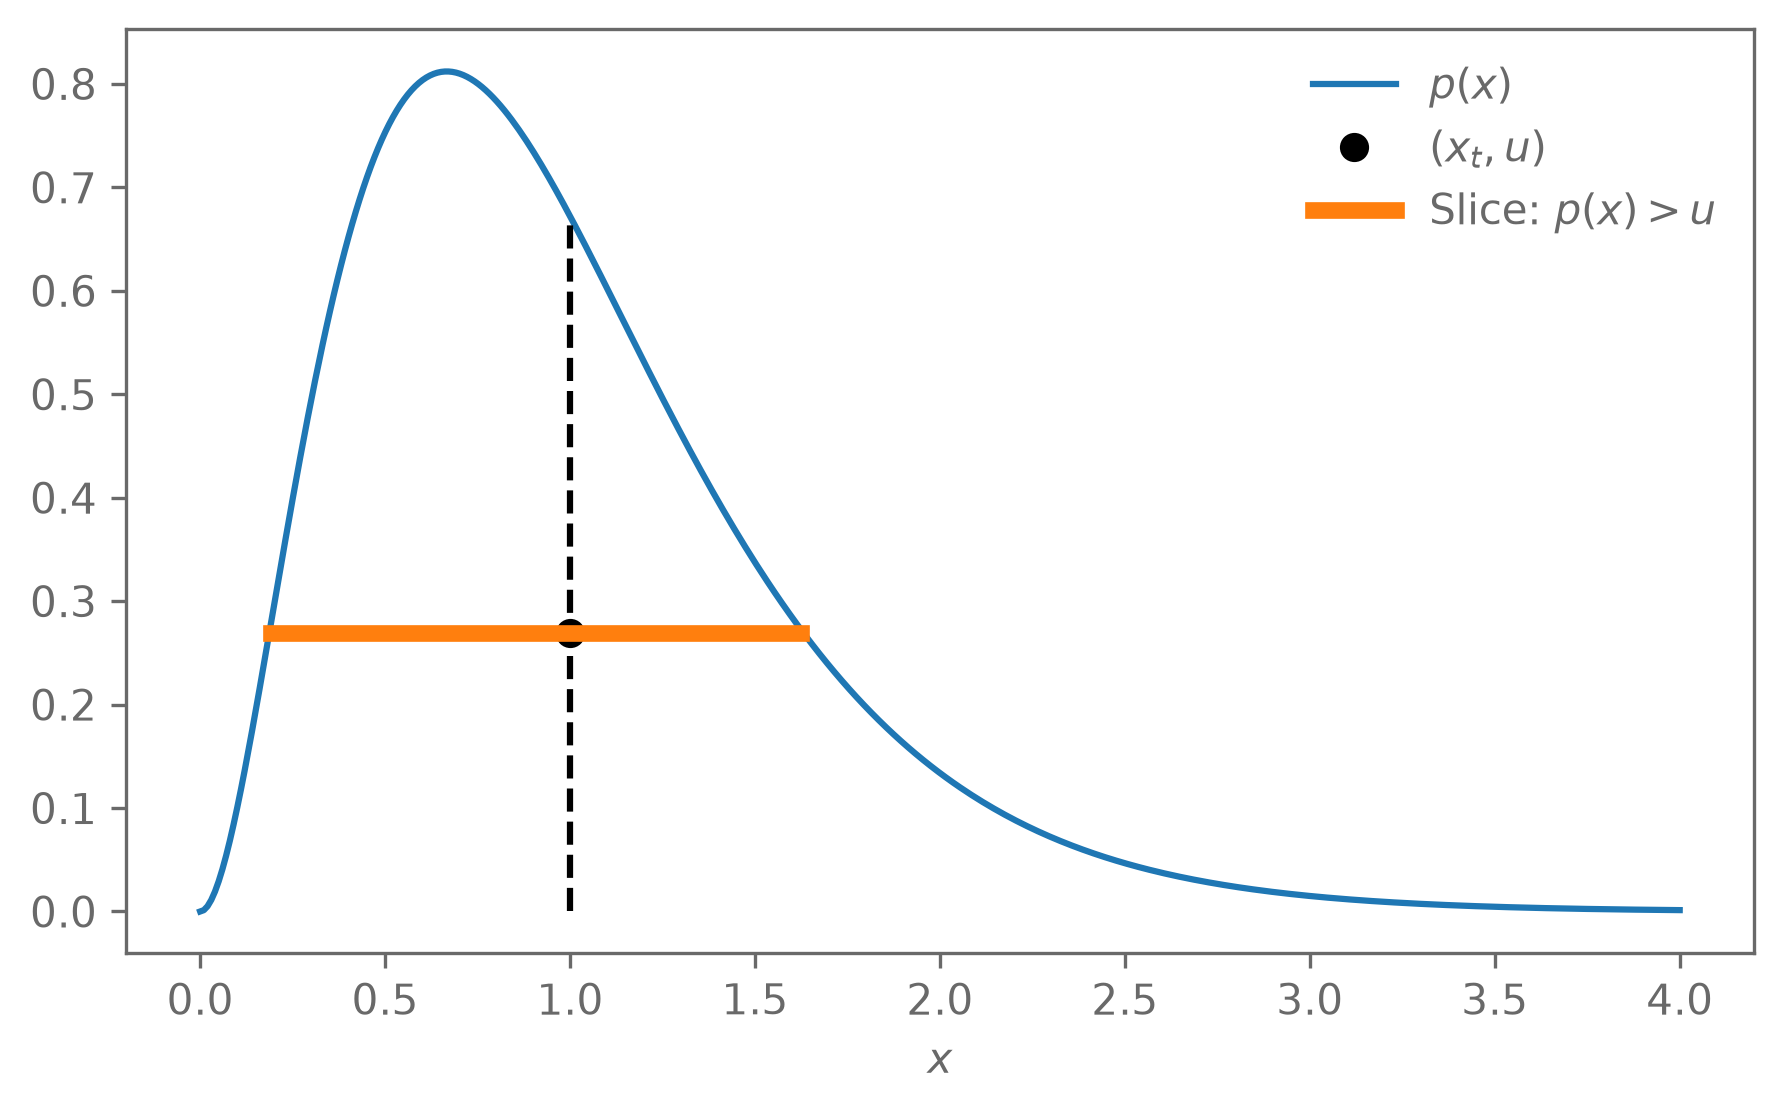

In [5]:
grid = np.linspace(0, 4, 400)
p = target_distr_1d.pdf(grid)

x_t = 1.0                          # current point of the chain
u = 0.4*target_distr_1d.pdf(x_t)   # a height below p(x_t)
in_slice = p > u                   # the slice: all x where p(x) > u

plt.plot(grid, p, label="$p(x)$")
plt.vlines(x_t, 0, target_distr_1d.pdf(x_t), color="k", ls="--")
plt.plot(x_t, u, "ko", label="$(x_t, u)$")
plt.plot(grid[in_slice], np.full(np.sum(in_slice), u), c="C1", lw=4,
         label="Slice: $p(x) > u$")
plt.xlabel("$x$")
plt.legend(frameon=False);

### Exercise 1: Slice sampling

- Implement your own slice sampler and sample from the 1D Gamma distribution. Compare a histogram of the samples to the PDF.
- How does the step size $w$ change the result? Try $w = 0.01, 1, 100$.

In [13]:
def slice_sampling(p,n_steps,step_size,x0):
    samples = np.empty((n_steps,x0.size))
    u_samples = samples
    w = step_size
    u_distr = scipy.stats.uniform(0,1.0)
    #sample u:
    for i in range(n_steps):
        u = u_distr.rvs() * p.pdf(x0)

        r = u_distr.rvs()
        x_l = x0 - r * w
        x_r = x0 + (1 - r) * w

        while p.pdf(x_l) > u:
            x_l -= w

        while p.pdf(x_r) > u:
            x_r += w


        LR_distr = scipy.stats.uniform(x_l,x_r)
        x = LR_distr.rvs()
        while p.pdf(x) <= u:
            if x > x0:
                x_r = x
            else:
                x_l = x
            x = LR_distr.rvs()

        x0 = x
        samples[i] = x0
        u_samples[i] = u

    return samples, u_samples


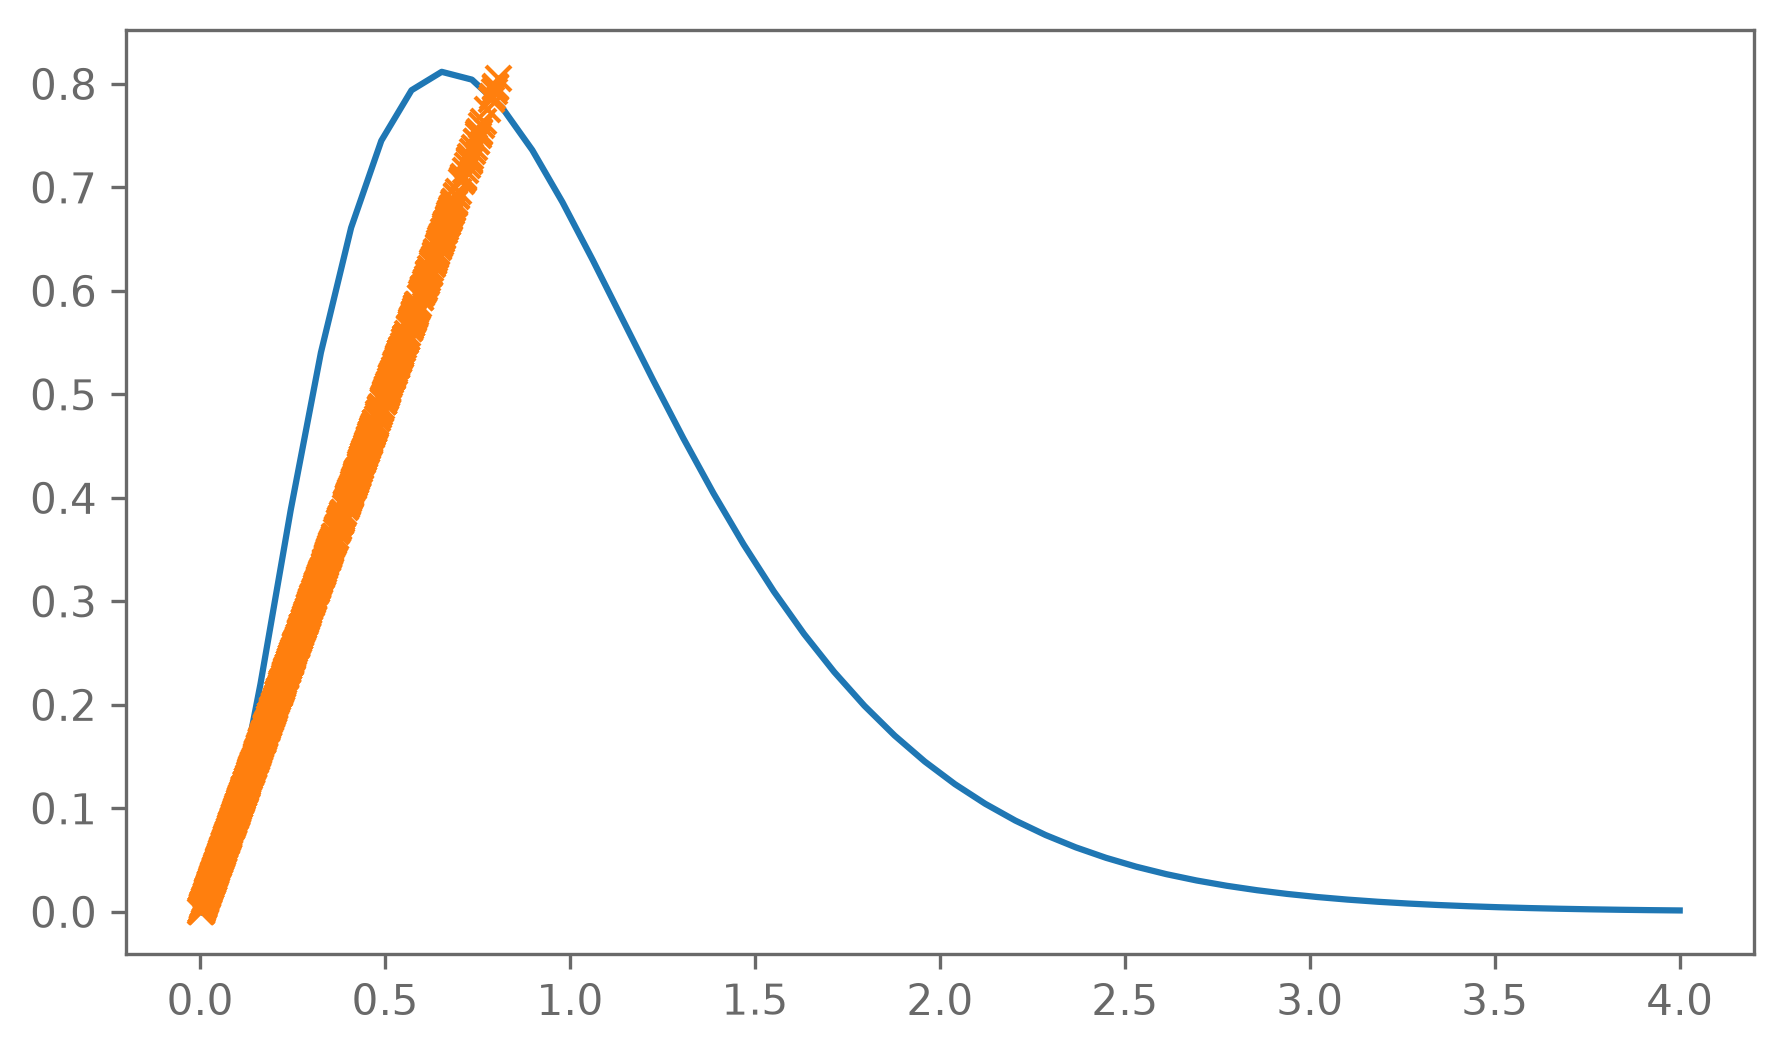

In [18]:
x0 = np.array([3.0])

x_samples, u_samples = slice_sampling(target_distr_1d,1000,0.01,x0)
x = np.linspace(0.0,4.0)


plt.plot(x,target_distr_1d.pdf(x))
plt.plot(x_samples, u_samples, ls=' ',marker = 'x')


### Exercise 2: Burn-in and auto-correlation

- Run your Metropolis-Hastings sampler (from week 5) and your slice sampler on the 1D Gamma distribution, starting far in the tail, e.g. at $x = 10$.
- Plot the chains. How long is the burn-in?
- After removing the burn-in, compute the auto-correlation time of each chain with `emcee.autocorr.integrated_time`. Which sampler gives more independent samples?

### Exercise 3: Nested sampling

- Implement your own nested sampling routine for $n$ dimensions. Use rejection sampling from the prior to find new live points, as in the lecture.
- Compute the evidence $Z$ for the 2D Gaussian likelihood with a uniform prior on $[-7, 7]^2$. Show that the exact answer is $Z \approx 1/14^2$ and compare.

### Exercise 4: emcee and dynesty

This is the main exercise of this week. We use the 2D Gaussian with a uniform prior on $[-7, 7]^2$.

- Sample the 2D Gaussian with `emcee`, starting all walkers close to $(5, -5)$. Plot the chains of the walkers. How long is the burn-in? Compute the auto-correlation time with `sampler.get_autocorr_time()`, then remove the burn-in and thin the chain.
- Sample the 2D Gaussian with `dynesty`. Look at `results.summary()` and at `dynesty.plotting.runplot`. What does the run plot show?
- Compare the samples to `true_samples` in a corner plot.
- Compare $\ln Z$ from `dynesty` to the exact value and to your own nested sampler.
- How many likelihood evaluations did `emcee`, `dynesty`, and your nested sampler need?
- Run `dynesty` with $n_\mathrm{live} = 50, 200, 1000$. How do the uncertainty on $\ln Z$ and the number of likelihood evaluations change?
- `emcee` and `dynesty` give the same posterior, but only `dynesty` gives $\ln Z$. To see why, add a constant (e.g. 10) to your log posterior and run `emcee` again with the same seed. Does anything change? What happens to $\ln Z$ in `dynesty` if you instead make the prior box twice as wide, $[-14, 14]^2$?

### Exercise 5 (Bonus): Model comparison

Go back to the line-fitting exercise and take the data in `lectures/data/linear_fits/data_2.txt`. Compare two models:

$$
\begin{aligned}
    M_1:&\quad \mu(x) = mx + b \\
    M_2:&\quad \mu(x) = ax^2 + bx + c
\end{aligned}
$$

Use the Gaussian likelihood $y_i\sim\mathcal{N}(\mu(x_i), \sigma_{y_i}^2)$ and uniform priors $\mathcal{U}(-3, 3)$ on all parameters.

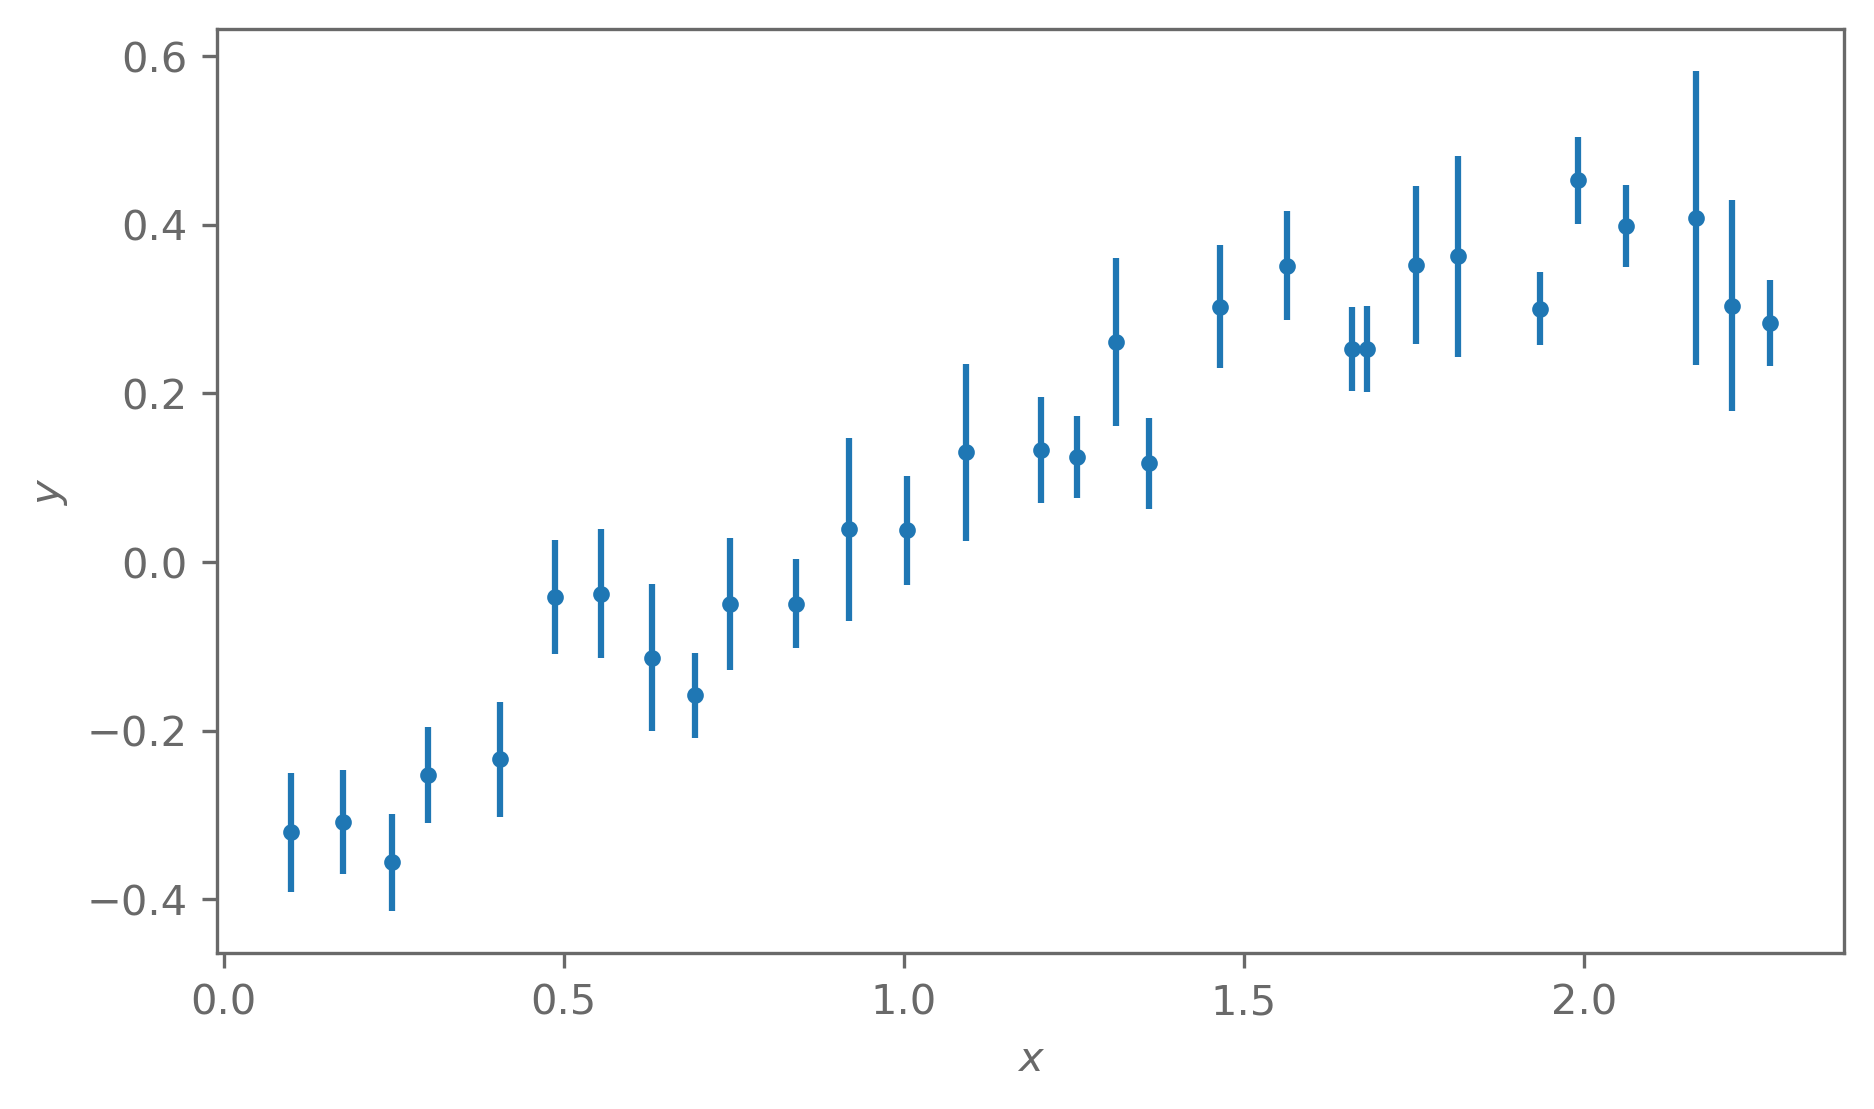

In [10]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)

plt.errorbar(x, y, y_err, fmt=".")
plt.xlabel("$x$")
plt.ylabel("$y$");

- Use `dynesty` to compute the evidence of each model. Which model is preferred by the data, and how strongly?
- Repeat with `data_0.txt`. Which model is preferred now?
- Widen the prior on $a$ to $\mathcal{U}(-30, 30)$. How do the posterior and the Bayes' ratio change?